# Прогноз цены бриллианта

Сравниваем линейную модель, дерево решений и два варианта градиентного
бустинга на исторических ценах в долларах. Цель — выбрать модель
с наименьшей средней абсолютной ошибкой по кросс-валидации и оценить
её качество на отложенной выборке.

Данные: [Diamonds на Kaggle](https://www.kaggle.com/datasets/ayeshaseherr/diamonds).
Локальная версия лежит в `data/diamonds.csv`; подробности — в README.
Перед запуском установите `requirements-notebook.txt` и выберите ядро проекта.
Выполняйте ячейки сверху вниз командой **Restart Kernel → Run All**.
Для запуска Streamlit после эксперимента используйте сохранённую в последней
ячейке модель.


In [11]:
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from threadpoolctl import threadpool_limits

from diamonds import CATEGORIES, DEFAULT_DATA, FEATURES, MODEL_PATH, NUMERIC, REPORT_PATH

pd.options.display.float_format = "{:.2f}".format

SEED = 42
print(f"Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}")

Python 3.13.2 | scikit-learn 1.7.2 | pandas 2.3.3


## 1. Подготовка и обзор данных

Парсим исходный файл с десятичными запятыми. Удаляем строки без цены и полные
дубликаты, исключаем ID из признаков. Нулевые и некорректные измерения считаем
пропусками. Медианы для заполнения измерений модель вычислит внутри каждого
обучающего фолда.

In [12]:
def load_data(path):
    frame = pd.read_csv(path, sep=None, engine="python", dtype="string",
                        na_values=["isntKnown"])
    required = FEATURES + ["price"]
    missing = set(required) - set(frame.columns)
    if missing:
        raise ValueError(f"Missing columns: {', '.join(sorted(missing))}")
    frame = frame[required].copy()
    for column in NUMERIC + ["price"]:
        values = pd.to_numeric(frame[column].str.replace(",", ".", regex=False),
                               errors="coerce").astype(float)
        frame[column] = values.where(np.isfinite(values) & (values > 0))
    for column, allowed in CATEGORIES.items():
        values = frame[column].str.strip()
        frame[column] = values.where(values.isin(allowed), "Unknown").astype(str)
    clean = frame.dropna(subset=["price"]).drop_duplicates().reset_index(drop=True)
    return clean, len(frame), int(frame["price"].isna().sum())

,Количество
Строк в исходнике,53940
Строк без корректной цены,24
Полных дубликатов,144
Строк для эксперимента,53772


,carat,depth,table,x,y,z,cut,color,clarity,price
0,0.23,61.50,55.00,3.95,3.98,2.43,Ideal,E,SI2,326.00
1,0.21,59.80,61.00,3.89,3.84,2.31,Premium,E,SI1,326.00
2,0.29,62.40,58.00,4.20,4.23,2.63,Premium,I,VS2,334.00
3,0.31,63.30,58.00,4.34,4.35,2.75,Good,J,SI2,335.00
4,0.24,62.80,57.00,3.94,3.96,2.48,Very Good,J,VVS2,336.00


,Пропуски после очистки
carat,22
depth,22
table,31
x,23
y,32
z,41
cut,0
color,0
clarity,0
price,0


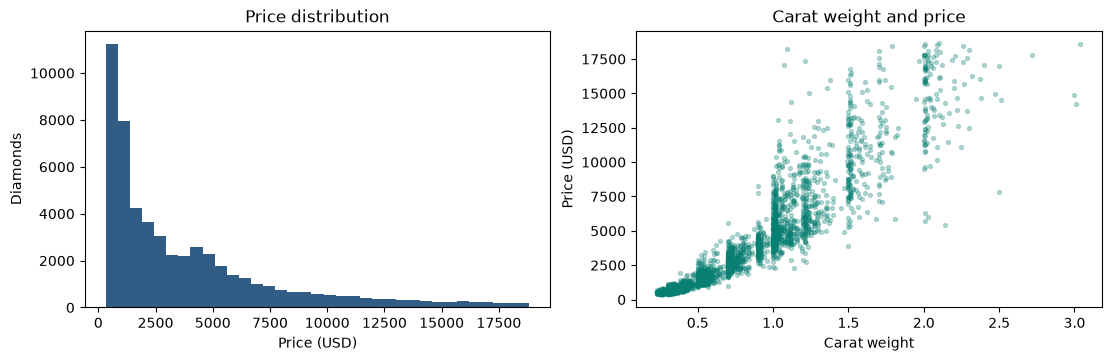

In [13]:
data, raw_rows, missing_target = load_data(DEFAULT_DATA)
duplicates = raw_rows - missing_target - len(data)
display(pd.Series({
    "Строк в исходнике": raw_rows,
    "Строк без корректной цены": missing_target,
    "Полных дубликатов": duplicates,
    "Строк для эксперимента": len(data),
}).to_frame("Количество"))
display(data.head())
display(data.isna().sum().to_frame("Пропуски после очистки"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
axes[0].hist(data["price"], bins=35, color="#315c85")
axes[0].set(xlabel="Price (USD)", ylabel="Diamonds", title="Price distribution")
sample = data.sample(n=3000, random_state=SEED)
axes[1].scatter(sample["carat"], sample["price"], s=8, alpha=0.28, color="#087f73")
axes[1].set(xlabel="Carat weight", ylabel="Price (USD)", title="Carat weight and price")
plt.show()

### Проверка некорректных измерений до заполнения пропусков

Сначала считаем отсутствующие, нечисловые, бесконечные и неположительные
значения в исходных числовых признаках.
Такие значения загрузчик переводит в пропуски, а pipeline заполняет их
медианами только по обучающей части.

In [14]:
raw_features = pd.read_csv(DEFAULT_DATA, sep=None, engine="python", dtype="string",
                           na_values=["isntKnown"])
numeric_audit = []
for column in NUMERIC:
    values = pd.to_numeric(raw_features[column].str.replace(",", ".", regex=False),
                           errors="coerce").astype(float)
    numeric_audit.append({
        "Признак": column,
        "Пропуск / не число": int(values.isna().sum()),
        "Бесконечность": int((values.notna() & ~np.isfinite(values)).sum()),
        "Ноль или отрицательное": int((np.isfinite(values) & (values <= 0)).sum()),
    })
display(pd.DataFrame(numeric_audit).set_index("Признак"))

,Пропуск / не число,Бесконечность,Ноль или отрицательное
Признак,,,
carat,22,0,0
depth,22,0,0
table,31,0,0
x,16,0,8
y,26,0,7
z,22,0,20


### Наблюдение: необычные размеры

В данных встречаются подозрительно большие положительные размеры: например,
ширина 58.90 мм при длине 8.09 мм или высота 31.80 мм у камня 0.51 карата.
Ниже приведены примеры, где хотя бы один размер больше 20 мм. Это условие
используется только для показа примеров, а не как правило очистки.

По файлу нельзя надёжно восстановить правильные значения. Поэтому эти записи
**оставляем без изменений** и включаем в обучение и оценку качества.
Отдельные фильтры аномалий и сравнение ошибок на них не используются.
Как и прежде, нулевые/отрицательные значения считаются пропусками,
а пропуски заполняются внутри pipeline.

In [15]:
large_dimensions = data[["x", "y", "z"]].gt(20).any(axis=1)
display(data.loc[large_dimensions, ["carat", "depth", "x", "y", "z"]]
        .style.format("{:.2f}", na_rep="—"))
print(f"Примеров с размером больше 20 мм: {int(large_dimensions.sum())}. Строки не удаляются.")

,carat,depth,x,y,z
24003,2.00,58.90,8.09,58.90,8.06
48246,0.51,61.80,5.12,5.15,31.80
49025,0.51,61.80,5.15,31.80,5.12


Примеров с размером больше 20 мм: 3. Строки не удаляются.


## 2. Разбиение и модели

Резервируем около 20% для итоговой оценки. Записи с одинаковыми входными
признаками имеют общий идентификатор группы и остаются вместе и при разбиении,
и при 5-фолдовой кросс-валидации. Выбираем модель по среднему MAE на фолдах.
Сравниваем Ridge, дерево решений и бустинг с 15 и 31 листом.
Ridge служит простой линейной точкой отсчёта; дерево и бустинг позволяют
учесть нелинейную связь характеристик с ценой.

In [16]:
def regression(estimator, numeric, categorical, scale=False):
    numeric_steps = [SimpleImputer(strategy="median")]
    if scale:
        numeric_steps.append(StandardScaler())
    preprocess = ColumnTransformer([
        ("numeric", make_pipeline(*numeric_steps), numeric),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ])
    return make_pipeline(preprocess, estimator)


def boosted(leaves):
    return HistGradientBoostingRegressor(
        max_iter=250, max_leaf_nodes=leaves, early_stopping=False,
        learning_rate=0.08, random_state=SEED,
    )


def metrics(actual, predicted):
    return {
        "mae_usd": float(mean_absolute_error(actual, predicted)),
        "rmse_usd": float(root_mean_squared_error(actual, predicted)),
        "r2": float(r2_score(actual, predicted)),
    }

In [17]:
x, y = data[FEATURES], data["price"]
groups = pd.util.hash_pandas_object(x, index=False)
split = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
train_idx, test_idx = next(split.split(x, y, groups))
x_train, x_test = x.iloc[train_idx], x.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
group_train = groups.iloc[train_idx]
assert set(group_train).isdisjoint(groups.iloc[test_idx])
print(f"Train: {len(train_idx):,} | Test: {len(test_idx):,}")

categorical = list(CATEGORIES)
candidates = {
    "Ridge": regression(Ridge(alpha=1.0), NUMERIC, categorical, scale=True),
    "Decision tree": regression(DecisionTreeRegressor(
        max_depth=14, min_samples_leaf=12, random_state=SEED), NUMERIC, categorical),
    "Boosting (15 leaves)": regression(boosted(15), NUMERIC, categorical),
    "Boosting (31 leaves)": regression(boosted(31), NUMERIC, categorical),
}

Train: 43,009 | Test: 10,763


## 3. Кросс-валидация

MAE — средняя абсолютная ошибка прогноза в долларах: чем меньше, тем лучше.
Стандартное отклонение показывает разброс MAE между пятью фолдами.
Денежные метрики отображаются с двумя знаками после запятой, R² — с тремя.
Форматирование не меняет точность вычислений и выбор модели.

Test отложен отдельно. Для каждой модели train делится на пять фолдов:
четыре части служат обучением, пятая — validation; затем роли меняются.
Победителя обучаем на всём train и оцениваем на полном test.

In [18]:
cv = GroupKFold(n_splits=5, shuffle=True, random_state=SEED)
scores = {}
with threadpool_limits(limits=2):
    for name, candidate in candidates.items():
        fold_mae = -cross_val_score(
            candidate, x_train, y_train, groups=group_train, cv=cv,
            scoring="neg_mean_absolute_error", error_score="raise",
        )
        scores[name] = {
            "cv_mae_usd": float(fold_mae.mean()),
            "cv_mae_std_usd": float(fold_mae.std(ddof=1)),
        }
winner = min(scores, key=lambda name: scores[name]["cv_mae_usd"])
cv_table = pd.DataFrame.from_dict(scores, orient="index").sort_values("cv_mae_usd")
display(cv_table.style.format("{:.2f}"))
print(f"Selected by cross-validation: {winner}")

,cv_mae_usd,cv_mae_std_usd
Boosting (31 leaves),283.32,4.86
Boosting (15 leaves),296.12,5.00
Decision tree,340.66,8.54
Ridge,742.71,10.70


Selected by cross-validation: Boosting (31 leaves)


## 4. Проверка на отложенной выборке и анализ ошибок

In [19]:
fitted_models = {}
predictions = {}
with threadpool_limits(limits=2):
    for name, candidate in candidates.items():
        fitted = clone(candidate).fit(x_train, y_train)
        prediction = fitted.predict(x_test)
        scores[name].update(metrics(y_test, prediction))
        fitted_models[name] = fitted
        predictions[name] = prediction

results = pd.DataFrame.from_dict(scores, orient="index").sort_values("cv_mae_usd")
display(results.style.format({column: "{:.3f}" if column == "r2" else "{:.2f}"
                              for column in results.columns}))
residuals = pd.DataFrame({"actual": y_test, "predicted": predictions[winner]})
bands = pd.cut(residuals["actual"], [0, 1000, 5000, 10000, np.inf],
               labels=["Up to $1,000", "$1,000–$5,000", "$5,000–$10,000", "Above $10,000"])
slices = []
for band, rows in residuals.groupby(bands, observed=True):
    error = rows["predicted"] - rows["actual"]
    slices.append({
        "actual_price_band": str(band), "rows": len(rows),
        "mae_usd": float(error.abs().mean()), "bias_usd": float(error.mean()),
    })
display(pd.DataFrame(slices).style.format({"mae_usd": "{:.2f}", "bias_usd": "{:.2f}"}))

,cv_mae_usd,cv_mae_std_usd,mae_usd,rmse_usd,r2
Boosting (31 leaves),283.32,4.86,281.36,540.71,0.981
Boosting (15 leaves),296.12,5.00,294.22,553.30,0.980
Decision tree,340.66,8.54,333.01,637.67,0.974
Ridge,742.71,10.70,737.41,1123.55,0.919


,actual_price_band,rows,mae_usd,bias_usd
0,"Up to $1,000",2902,61.84,13.03
1,"$1,000–$5,000",4918,190.46,25.74
2,"$5,000–$10,000",1913,497.42,45.60
3,"Above $10,000",1030,932.64,-66.58


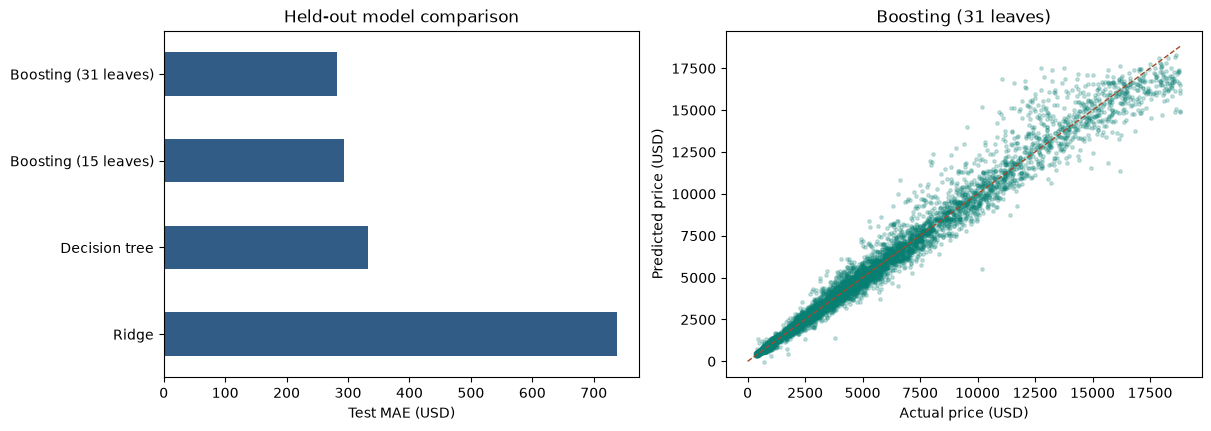

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), layout="constrained")
results["mae_usd"].sort_values(ascending=False).plot.barh(ax=axes[0], color="#315c85")
axes[0].set(xlabel="Test MAE (USD)", title="Held-out model comparison")
axes[1].scatter(residuals["actual"], residuals["predicted"], s=6, alpha=0.22, color="#087f73")
diagonal = [0, max(residuals.max())]
axes[1].plot(diagonal, diagonal, "--", color="#a24a29", linewidth=1)
axes[1].set(xlabel="Actual price (USD)", ylabel="Predicted price (USD)", title=winner)
plt.show()


### Какие признаки важны для прогноза

**Permutation importance:** фиксируем обученную модель, перемешиваем один
исходный столбец тестовой выборки и считаем прирост MAE. Чем больше прирост,
тем сильнее модель зависит от информации в этом признаке. Категории
перемешиваются до one-hot encoding, поэтому оцениваются целиком.
Используем всю тестовую выборку и 10 повторов с фиксированным seed.

Масса и размеры коррелируют: столбцы могут заменять друг друга, а независимое
перемешивание создаёт физически необычные сочетания. Поэтому дополнительно
перемешиваем массу и размеры совместно, одной перестановкой строк.
Так сохраняются связи внутри группы. Также проверяем качество и пропорции.
Это зависимость конкретной модели, **не причинное влияние на рыночную цену**.
Отрицательные значения не скрываем; разброс между перестановками не является
доверительным интервалом. Модель по этому анализу не перенастраиваем.

,feature,mae_increase_usd,repeat_std_usd
0,carat,2185.11,11.78
1,y,1094.26,7.09
2,clarity,643.81,6.86
3,color,409.51,4.35
4,x,194.02,2.04
5,z,192.47,2.04
6,cut,25.16,1.00
7,depth,11.57,0.44
8,table,4.20,0.43


,group,mae_increase_usd,repeat_std_usd
0,Масса и размеры,4107.02,35.60
1,Качество,905.07,5.73
2,Пропорции,14.46,0.74


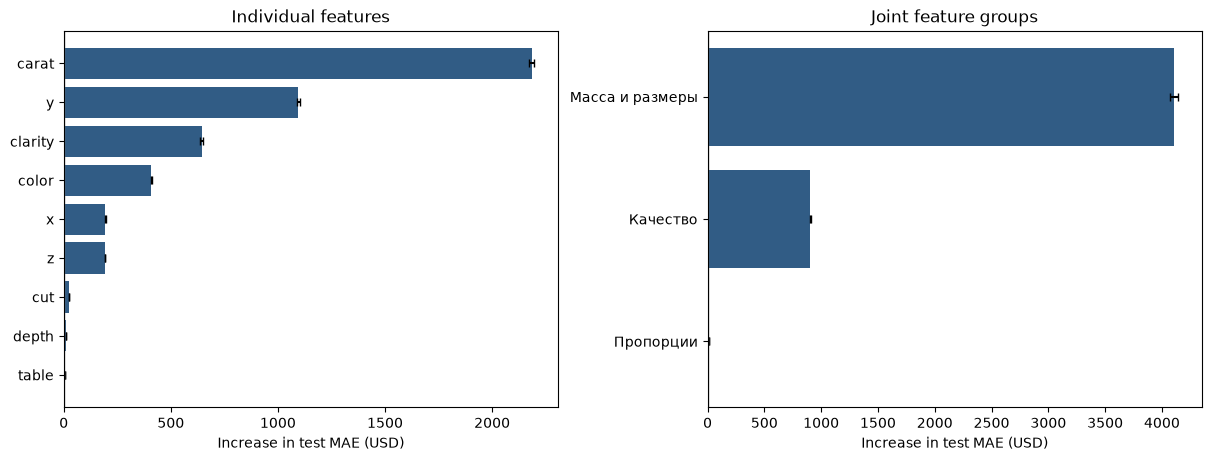

,carat,x,y,z
carat,1.00,1.00,1.00,0.99
x,1.00,1.00,1.00,0.99
y,1.00,1.00,1.00,0.99
z,0.99,0.99,0.99,1.00


**Вывод.** Самый большой прирост MAE при отдельном перемешивании — у **carat**: **$2185.11**. Среди групп лидирует **Масса и размеры**: **$4107.02**. Эти величины нельзя складывать или трактовать как доли цены. Таблица корреляций по train помогает увидеть взаимозаменяемость массы и размеров.

In [21]:
N_REPEATS = 10
selected_estimator = fitted_models[winner]
with threadpool_limits(limits=2):
    importance = permutation_importance(
        selected_estimator, x_test, y_test,
        scoring="neg_mean_absolute_error", n_repeats=N_REPEATS,
        random_state=SEED, n_jobs=1,
    )
importance_table = pd.DataFrame({
    "feature": x_test.columns,
    "mae_increase_usd": importance.importances_mean,
    "repeat_std_usd": importance.importances_std,
}).sort_values("mae_increase_usd", ascending=False).reset_index(drop=True)

feature_groups = {
    "Масса и размеры": ["carat", "x", "y", "z"],
    "Качество": ["cut", "color", "clarity"],
    "Пропорции": ["depth", "table"],
}
group_importances = []
base_mae = mean_absolute_error(y_test, predictions[winner])
with threadpool_limits(limits=2):
    for group_name, columns in feature_groups.items():
        rng = np.random.default_rng(SEED)
        increases = []
        for _ in range(N_REPEATS):
            shuffled = x_test.copy()
            order = rng.permutation(len(x_test))
            shuffled.loc[:, columns] = x_test.iloc[order][columns].to_numpy()
            increases.append(mean_absolute_error(y_test, selected_estimator.predict(shuffled)) - base_mae)
        group_importances.append({
            "group": group_name,
            "mae_increase_usd": float(np.mean(increases)),
            "repeat_std_usd": float(np.std(increases)),
        })
group_importance_table = pd.DataFrame(group_importances).sort_values(
    "mae_increase_usd", ascending=False).reset_index(drop=True)
for table in [importance_table, group_importance_table]:
    display(table.style.format({"mae_increase_usd": "{:.2f}", "repeat_std_usd": "{:.2f}"}))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
for axis, table, column, title in [
    (axes[0], importance_table, "feature", "Individual features"),
    (axes[1], group_importance_table, "group", "Joint feature groups"),
]:
    ordered = table.sort_values("mae_increase_usd")
    axis.barh(ordered[column], ordered["mae_increase_usd"],
              xerr=ordered["repeat_std_usd"], color="#315c85", capsize=3)
    axis.axvline(0, color="gray", linewidth=1)
    axis.set(xlabel="Increase in test MAE (USD)", title=title)
plt.show()

size_correlations = x_train[["carat", "x", "y", "z"]].corr(method="spearman")
display(size_correlations.style.format("{:.2f}"))
top_feature = importance_table.iloc[0]
top_group = group_importance_table.iloc[0]
display(Markdown(
    f"**Вывод.** Самый большой прирост MAE при отдельном перемешивании — у "
    f"**{top_feature['feature']}**: **${top_feature['mae_increase_usd']:.2f}**. "
    f"Среди групп лидирует **{top_group['group']}**: **${top_group['mae_increase_usd']:.2f}**. "
    "Эти величины нельзя складывать или трактовать как доли цены. "
    "Таблица корреляций по train помогает увидеть взаимозаменяемость массы и размеров."
))

Сравнение относится к этому историческому датасету и этому разбиению.
MAE по диапазону показывает среднюю величину ошибки по группе, а средняя
ошибка со знаком показывает направление смещения. В новых рыночных условиях
ошибки могут отличаться. Эти показатели не являются доверительным интервалом
для отдельного прогноза.

## 5. Сохранение модели для Streamlit

Ячейка сохраняет выбранную модель со всеми признаками и отчёт для приложения.


In [22]:
report = {
    "data_sha256": hashlib.sha256(DEFAULT_DATA.read_bytes()).hexdigest(),
    "seed": SEED, "raw_rows": raw_rows, "missing_price_rows": missing_target,
    "duplicate_rows": duplicates, "train_rows": len(train_idx), "test_rows": len(test_idx),
    "selected_model": winner, "models": scores, "price_slices": slices,
    "feature_importance": importance_table.to_dict(orient="records"),
    "grouped_feature_importance": group_importance_table.to_dict(orient="records"),
    "importance_repeats": N_REPEATS,
}
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
joblib.dump({"model": fitted_models[winner], "report": report}, MODEL_PATH, compress=3)
REPORT_PATH.write_text(json.dumps(report, indent=2, ensure_ascii=False) + "\n",
                       encoding="utf-8")
print("Saved:", MODEL_PATH.name, "and", REPORT_PATH.name)


Saved: model.joblib and benchmark.json
